In [1]:
##################
### Keagan Moo ###
### 2023/08/15 ###
### Chrom Stat ###
##################

suppressPackageStartupMessages({library(tidyverse)
library(matrixStats)
library(dplyr)
library(ggrepel)
#library(optparse)
library(glue)
library(data.table)
library(tidyverse)
library(tidyr)
library(ggplot2)
library(hash)
library(RColorBrewer)
library(pheatmap)
library("ggpattern")
                               })

Warning message:
“package ‘ggpattern’ was built under R version 4.4.3”


In [2]:
# Poterntially Iterate through possible cell types in future
Types <- c(
  "Type_1",
  "Type_2a",
  "Type_2x")
cDex <- "Type_2x"

In [3]:
# Load in background
    # Metadata produced the same way as kgmoo_linear.R
    message("Loading metadata")
    metadata.factors <- readRDS("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts/metadata.factors")
    peaks_dir <- file.path("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/",
                           "arushivData20220415/fusion_150_ccc")
    message("Loading background peaks")
    peaks <- file.path(peaks_dir, glue("atac.{cDex}.ccc.tsv")) %>%
      fread(data.table = F) %>%
      tibble::column_to_rownames("feature") %>%
      data.matrix()
    
    peaks <- peaks[, colnames(peaks) != "V1"]
    
    # Put everything in the same order and remove samples with missing age
    peaks <- peaks[,colnames(peaks) %in% rownames(metadata.factors)]
    metadata.factors <- metadata.factors[metadata.factors$sample %in% colnames(peaks),]
    peaks <- peaks[,rownames(metadata.factors)]
    peaksBed <- rownames(peaks)
    peaksBedDF <- t(data.frame(strsplit(peaksBed, split = ":")))
    rownames(peaksBedDF) <- NULL
    colnames(peaksBedDF) <- NULL

Loading metadata

Loading background peaks

Warning message in fread(., data.table = F):
“Detected 286 column names but the data has 287 columns (i.e. invalid file). Added 1 extra default column name for the first column which is guessed to be row names or an index. Use setnames() afterwards if this guess is not correct, or fix the file write command that created the file to create a valid file.”


In [ ]:
##############################################################
### RUN BED TOOLS COMMMANDS in bed2tsv file in this folder ### <- CONCERN: 149,751 peaks turns into 211,495
############################################################## <- with duplicated peaks identified

In [4]:
peaksDF <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/chromatinRM/{cDex}_bgoChrom_AdultFemale.tsv"), sep = "\t")
#peaksDF <- read.table(glue("/lab/work/kgmoo/ARIMAke/chromatinRM/Type_2x_bgoChrom_AdultFemale.tsv"), sep = "\t")
peaksEns <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/enrich/{cDex}_bgoEns.tsv"), sep = "\t")[,c("V1", "V2", "V3", "V10")]
    
colnames(peaksDF) <- c("peak_chromosome", "peak_startPosition", "peak_endPosition", "state_chromosome", "state_startPosition", "state_endPosition", "State")
colnames(peaksEns) <- c("peak_chromosome", "peak_startPosition", "peak_endPosition", "Distance")
    
peaksEns$Distance <- abs(peaksEns$Distance)
peaksEns <- peaksEns %>% distinct(peak_chromosome, peak_startPosition, peak_endPosition, Distance, .keep_all=TRUE)

In [8]:
dim(peaksDF)
table(peaksDF$State)

[1] 226088      7


                      .         Active_enhancer              Active_TSS 
                    829                   59861                   16982 
      Bivalent_enhancer            Bivalent_TSS       Flanking_bivalent 
                   4405                    2613                    4129 
 Flanking_transcription            Flanking_TSS          Genic_enhancer 
                    700                   22257                    6680 
        Heterochromatin    Quiescent_low_signal      Repressed_polycomb 
                    342                   35966                    7377 
   Strong_transcription Weak_repressed_polycomb      Weak_transcription 
                  12390                   15602                   35748 
       ZNF_gene_repeats 
                    207 

In [5]:
pListStates <- c("Active_TSS", "Strong_transcription",
                     "Weak_transcription", "Genic_enhancer", "Active_enhancer", 
                     "Bivalent_TSS", "Bivalent_enhancer",
                     "Repressed_polycomb", "Weak_repressed_polycomb", "Quiescent_low_signal",
                "Flanking_TSS", "Flanking_transcription", "Flanking_bivalent", "Heterochromatin", "ZNF_gene_repeats")
    rListStates <- c(".")
    
    peaksDF <- peaksDF[peaksDF$State %in% pListStates,]
    
    peaksDF <- left_join(peaksDF, peaksEns, by=c("peak_chromosome", "peak_startPosition", "peak_endPosition"))
    
    if (!all(rownames(metadata.factors) == colnames(peaks))) {
      stop("Something wrong (1)")
    }
    
    libsizes <- colSums(peaks)
    peaksizes <- data.frame(peaKey=rownames(peaks), median=rowMedians(peaks))
    
    if (all(names(libsizes) == metadata.factors$sample)) {
      message("Adding library sizes to meta data")
      metadata.factors$libsize <- log2(unname(libsizes))
    } else {
      stop("Something wrong (2)")
    }

Adding library sizes to meta data



In [6]:
# Load GLMNB peaks
#GLMNBSelected <- readRDS(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/Summary"))
GLMNBSelectedF <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/F_pTSS_Agg_{cDex}.tsv"), sep = "\t", header = TRUE)
#write.csv(fCCluster_Linear_nom, file =glue("/lab/work/kgmoo/ARIMAke/albanusScripts/KMOutCCC/linear_per_cluster/{Type}_glmoff_female.csv"))
GLMNBSelectedM <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/results/lmm/Agg/M_pTSS_Agg_{cDex}.tsv"), sep = "\t", header = TRUE)
#write.csv(mCCluster_Linear_nom, file =glue("/lab/work/kgmoo/ARIMAke/albanusScripts/KMOutCCC/linear_per_cluster/{Type}_glmoff_male.csv"))

In [7]:
fComp <- GLMNBSelectedF %>% dplyr::select("estimate", "p_FDR") %>% dplyr::filter(p_FDR < 0.05)
fCompUP <- fComp %>% dplyr::filter (estimate > 0)
fCompDOWN <- fComp %>% dplyr::filter (estimate < 0)
mComp <- GLMNBSelectedM %>% dplyr::select("estimate", "p_FDR") %>% dplyr::filter(p_FDR < 0.05)
mCompUP <- mComp %>% dplyr::filter (estimate > 0)
mCompDOWN <- mComp %>% dplyr::filter (estimate < 0)

In [8]:
fSelectGLM <- data.frame(Select = rownames(fComp))
fSelectGLMUP <- data.frame(Select = rownames(fCompUP))
fSelectGLMDOWN <- data.frame(Select = rownames(fCompDOWN))
mSelectGLM <- data.frame(Select = rownames(mComp))
mSelectGLMUP <- data.frame(Select = rownames(mCompUP))
mSelectGLMDOWN <- data.frame(Select = rownames(mCompDOWN))
fpeaksSelectedGLM <- unique(fSelectGLM$Select)
fpeaksSelectedGLMUP <- unique(fSelectGLMUP$Select)
fpeaksSelectedGLMDOWN <- unique(fSelectGLMDOWN$Select)
mpeaksSelectedGLM <- unique(mSelectGLM$Select)
mpeaksSelectedGLMUP <- unique(mSelectGLMUP$Select)
mpeaksSelectedGLMDOWN <- unique(mSelectGLMDOWN$Select)

In [9]:
AgePeaks <- readRDS(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts_Update/Res/ChromEnrich/AgePeaks_{cDex}_GLMMNB_05.rds"))

In [10]:
nucData <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/enrich/{cDex}_Nuc.tsv"), sep = "\t")
colnames(nucData) <- c("chr", "start", "end", "ATp", "GCp", "Act", "Cct", "Gct", "Tct", "Nct", "Otherct", "Total_Length")
nucData$peaKey <- paste(nucData$chr, nucData$start, 
                        nucData$end, sep=":")
GCData <- nucData %>% dplyr::select(c("peaKey", "GCp"))

In [11]:
### PART 2: Organize dataframes by calculating whether each peak overlaps with each possible region
peaKey <- paste(peaksDF$peak_chromosome, peaksDF$peak_startPosition, 
                peaksDF$peak_endPosition, sep=":")
inputDF <- data.frame(peaKey)
inputDF$peakGene <- peaksDF$Gene
inputDF$peakEns <- peaksDF$GeneEns

inputDF$fSelectedGLM <- as.integer(inputDF$peaKey %in% 
                                    fpeaksSelectedGLM)
inputDF$mSelectedGLM <- as.integer(inputDF$peaKey %in% 
                                    mpeaksSelectedGLM)
inputDF$fSelectedGLMUP <- as.integer(inputDF$peaKey %in% 
                                    fpeaksSelectedGLMUP)
inputDF$mSelectedGLMUP <- as.integer(inputDF$peaKey %in% 
                                    mpeaksSelectedGLMUP)
inputDF$fSelectedGLMDOWN <- as.integer(inputDF$peaKey %in% 
                                        fpeaksSelectedGLMDOWN)
inputDF$mSelectedGLMDOWN <- as.integer(inputDF$peaKey %in% 
                                        mpeaksSelectedGLMDOWN)
inputDF$Distal5kb <- as.integer(peaksDF$Distance > 5000)
inputDF <- merge(inputDF, peaksizes, by = "peaKey")
inputDF <- merge(inputDF, GCData, by = "peaKey")
    
inputDF <- inputDF[!duplicated(inputDF), ]
duPeaks <- inputDF[duplicated(inputDF$peaKey),]$peaKey

In [22]:
peaksDFPlot <- peaksDF
peaksDFPlot$peaKey <- paste(peaksDF$peak_chromosome, peaksDF$peak_startPosition, 
                peaksDF$peak_endPosition, sep=":")
peaksDFPlot$peakSet <- "None"
#peaksDFPlot[peaksDFPlot$peaKey %in% fpeaksSelectedGLM,]$peakSet <- "Female Total"
peaksDFPlot[peaksDFPlot$peaKey %in% fpeaksSelectedGLMUP,]$peakSet <- "Female Opening"
peaksDFPlot[peaksDFPlot$peaKey %in% fpeaksSelectedGLMDOWN,]$peakSet <- "Female Closing"
fUPFrame <- data.frame(table(peaksDFPlot[peaksDFPlot$peakSet == "Female Opening",]$State)/nrow(peaksDFPlot[peaksDFPlot$peakSet == "Female Opening",]))
fUPFrame$Set <- "FDR < 0.1 Female Opening"
fUPFrame$Sex <- "Female"
fUPFrame$Pattern <- "Opening"
fDWFrame <- data.frame(table(peaksDFPlot[peaksDFPlot$peakSet == "Female Closing",]$State)/nrow(peaksDFPlot[peaksDFPlot$peakSet == "Female Closing",]))
fDWFrame$Set <- "FDR < 0.1 Female Closing"
fDWFrame$Sex <- "Female"
fDWFrame$Pattern <- "Closing"

#peaksDFPlot[peaksDFPlot$peaKey %in% mpeaksSelectedGLM,]$peakSet <- "Male Total"
peaksDFPlot[peaksDFPlot$peaKey %in% mpeaksSelectedGLMUP,]$peakSet <- "Male Opening"
peaksDFPlot[peaksDFPlot$peaKey %in% mpeaksSelectedGLMDOWN,]$peakSet <- "Male Closing"
mUPFrame <- data.frame(table(peaksDFPlot[peaksDFPlot$peakSet == "Male Opening",]$State)/nrow(peaksDFPlot[peaksDFPlot$peakSet == "Male Opening",]))
mUPFrame$Set <- "FDR < 0.1 Male Opening"
mUPFrame$Sex <- "Male"
mUPFrame$Pattern <- "Opening"
mDWFrame <- data.frame(table(peaksDFPlot[peaksDFPlot$peakSet == "Male Closing",]$State)/nrow(peaksDFPlot[peaksDFPlot$peakSet == "Male Closing",]))
mDWFrame$Set <- "FDR < 0.1 Male Closing"
mDWFrame$Sex <- "Male"
mDWFrame$Pattern <- "Closing"

peaksDFPlot[peaksDFPlot$peaKey %in% AgePeaks,]$peakSet <- "P > 0.5 Age-Association"

outFrame <- data.frame(table(peaksDFPlot[peaksDFPlot$peakSet == "P > 0.5 Age-Association",]$State)/nrow(peaksDFPlot[peaksDFPlot$peakSet == "P > 0.5 Age-Association",]))
outFrame$Set <- "P > 0.5 Age-Association"
outFrame$Sex <- "P > 0.5 Age-Association"
outFrame$Pattern <- "Not Associated"

plotFrame <- rbind(outFrame, fUPFrame, fDWFrame)
plotfraMe <- rbind(outFrame, mUPFrame, mDWFrame)
colnames(plotFrame) <- c("State","Percent","Set", "Sex", "Pattern")
colnames(plotfraMe) <- c("State","Percent","Set", "Sex", "Pattern")
head(plotFrame, n = 20)

,State,Percent,Set,Sex,Pattern
,<fct>,<dbl>,<chr>,<chr>,<chr>
1,Active_enhancer,2.606195e-01,P > 0.5 Age-Association,P > 0.5 Age-Association,Not Associated
2,Active_TSS,2.817829e-01,P > 0.5 Age-Association,P > 0.5 Age-Association,Not Associated
3,Bivalent_enhancer,8.702452e-03,P > 0.5 Age-Association,P > 0.5 Age-Association,Not Associated
4,Bivalent_TSS,7.769145e-03,P > 0.5 Age-Association,P > 0.5 Age-Association,Not Associated
5,Flanking_bivalent,1.495813e-02,P > 0.5 Age-Association,P > 0.5 Age-Association,Not Associated
6,Flanking_transcription,9.610534e-03,P > 0.5 Age-Association,P > 0.5 Age-Association,Not Associated
7,Flanking_TSS,2.974473e-01,P > 0.5 Age-Association,P > 0.5 Age-Association,Not Associated
8,Genic_enhancer,2.931087e-02,P > 0.5 Age-Association,P > 0.5 Age-Association,Not Associated
9,Heterochromatin,1.513470e-04,P > 0.5 Age-Association,P > 0.5 Age-Association,Not Associated


In [23]:
plotFrame$State <- factor(plotFrame$State, levels = c("Active_enhancer", "Genic_enhancer", "Bivalent_enhancer",   
                 "Quiescent_low_signal", "Weak_repressed_polycomb", "Repressed_polycomb", "Heterochromatin", 
                  "Weak_transcription", "Strong_transcription", "Flanking_transcription", "ZNF_gene_repeats", "Flanking_bivalent", "Bivalent_TSS", "Flanking_TSS", "Active_TSS"))


plotfraMe$State <- factor(plotfraMe$State, levels = c("Active_enhancer", "Genic_enhancer", "Bivalent_enhancer",   
                 "Quiescent_low_signal", "Weak_repressed_polycomb", "Repressed_polycomb", "Heterochromatin", 
                  "Weak_transcription", "Strong_transcription", "Flanking_transcription", "ZNF_gene_repeats", "Flanking_bivalent", "Bivalent_TSS", "Flanking_TSS", "Active_TSS"))

plotfraMe$State <- gsub("_", " ", plotfraMe$State)
plotfraMe$State <- factor(plotfraMe$State, levels = c("Active enhancer", "Genic enhancer", "Bivalent enhancer",   
                 "Quiescent low signal", "Weak repressed polycomb", "Repressed polycomb", "Heterochromatin", 
                  "Weak transcription", "Strong transcription", "Flanking transcription", "ZNF gene repeats", "Flanking bivalent", "Bivalent TSS", "Flanking TSS", "Active TSS"))

In [14]:
#c("Active_enhancer", "Genic_enhancer", "Bivalent_enhancer",   
#                 "Quiescent_low_signal", "Weak_repressed_polycomb", "Repressed_polycomb", "Heterochromatin", 
#                  "Weak_transcription", "Strong_transcription", "Flanking_transcription", "ZNF_gene_repeats", "Flanking_bivalent", "Bivalent_TSS", "Flanking_TSS", "Active_TSS"))
RoadMapPal <- c("#FFFF00", "#C2E105", "#BDB76B", 
                "#FFFFFF", "#C0C0C0", "#080808", "#8A91D0",
                "#006400", "#008000", "#32CD32", "#66CDAA", "#E9967A", "#CD5C5C", "#FF4500", "#FF0000")

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/ATACEnrich_{cDex}_Female_Stacks.pdf"), width=3, height=5)
mygg <- ggplot(plotFrame, aes(x = Pattern, y = Percent, fill = State)) +
  geom_bar(stat = "identity", color = "#000000") +
  xlab("") + ylab("Fraction of Peaks") + ggtitle(glue("")) +
  theme_bw() + 
  theme(text=element_text(size=24), axis.text.x = element_text(angle = 45, vjust = 1, hjust=1), legend.position="none") +
  scale_fill_manual(values = RoadMapPal) #+
  #scale_y_continuous(breaks=seq(-4,4,0.5), limits = c(-4,4)) + theme_bw() +
mygg
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/ATACEnrich_{cDex}_Male_Stacks.pdf"), width=3, height=5)
mygg <- ggplot(plotfraMe, aes(x = Pattern, y = Percent, fill = State)) +
  geom_bar(stat = "identity", color = "#000000") +
  xlab("") + ylab("Fraction of Peaks") + ggtitle(glue("")) +
  theme_bw() + 
  theme(text=element_text(size=24), axis.text.x = element_text(angle = 45, vjust = 1, hjust=1), legend.position="none") +
  scale_fill_manual(values = RoadMapPal) #+
  #scale_y_continuous(breaks=seq(-4,4,0.5), limits = c(-4,4)) + theme_bw() +
  #guides(fill=guide_legend(ncol=2))
mygg
dev.off()



pdf 
  2

pdf 
  2

pdf 
  2

In [24]:
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/ATACEnrich_LedgeStacksTall.pdf"), width=4, height=6)
mygg <- ggplot(plotfraMe, aes(x = Pattern, y = Percent, fill = State)) +
  geom_bar(stat = "identity") +
  xlab("") + ylab("Fraction of Peaks") + ggtitle(glue("")) +
  theme_bw() + 
  theme(text=element_text(size=24), axis.text.x = element_text(angle = 45, vjust = 1, hjust=1), legend.key=element_rect(colour='black')) +
  scale_fill_manual(values = RoadMapPal) +
  #scale_y_continuous(breaks=seq(-4,4,0.5), limits = c(-4,4)) + theme_bw() +
  guides(fill=guide_legend(ncol=1))
mygg
dev.off()

#ggplot(df, aes(x = x, fill = group)) + 
#  geom_bar()

pdf 
  2

In [14]:
stateTerms <- peaksDF[,c(7,1,2,3)]
    
peaKollapse <- paste(stateTerms$peak_chromosome, stateTerms$peak_startPosition, 
                stateTerms$peak_endPosition, sep=":")
stateTerms$peakCoord <- peaKollapse
statePeaks <- stateTerms[,c(1,5)]
stateTerms <- statePeaks %>% group_by(State) %>% summarise(peakCoord = list(peakCoord))
stateCount <- statePeaks %>% group_by(State) %>% dplyr::count()

In [15]:
FauxRaux <- c(rep(c(0,1,-1),length(pListStates)))
setList <- c("F GLM", "M GLM", 
            "F GLM UP", "M GLM UP", "F GLM DOWN", "M GLM DOWN")
models <- data.frame(replicate(length(setList), FauxRaux, simplify=FALSE))
colnames(models) <- setList
pListStateC <- paste0(pListStates, " Coef")
pListStateP <- paste0(pListStates, " PNom")
pListStateE <- paste0(pListStates, " StdE")
# Interleaves the strings and then sets them to row names
rownames(models) <- c(rbind(pListStateC,pListStateP,pListStateE))
    
tryModel <- function(FUNformula, FUNinput, ...) {
   tempModel <- tryCatch(
     expr = {
       tempModel <- glm(formula = FUNformula, family="binomial", data=FUNinput)
     }, 
     error = function(e){
       print(glue("{tempName} suffered a fatal error"))
       tempModel <- -1
     }, 
     warning = function(w){
       print(glue("{tempName} suffered a warning"))
       tempModel <- -1
     }, 
     finally = {
       #pass
     }) 
   return(tempModel)
}

for (sDex in 1:nrow(stateTerms)){
      
  tempName <- stateTerms[sDex,1]
  print(tempName)
  inputDF[glue("{tempName}")] <- as.integer(inputDF$peaKey %in% noquote(stateTerms$peakCoord[[sDex]]))
     
}
    
setSet <- c("fSelectedGLM", "mSelectedGLM", 
            "fSelectedGLMUP", "mSelectedGLMUP", 
            "fSelectedGLMDOWN", "mSelectedGLMDOWN")
    
peakSetSet <- list(fpeaksSelectedGLM, mpeaksSelectedGLM,
                       fpeaksSelectedGLMUP, mpeaksSelectedGLMUP,
                       fpeaksSelectedGLMDOWN, mpeaksSelectedGLMDOWN)

for (pDex in 1:length(setSet)) {
   tempPeak <- setSet[pDex]
   #print(tempPeak)
   tempPeakSet <- peakSetSet[pDex]
   #print(glue(length(tempPeakSet[[1]]), " out of ", length(AgePeaks)))
   tempAgePeaks <- dplyr::setdiff(AgePeaks, tempPeakSet[[1]])
   #print(length(tempAgePeaks))
   tempInputDF <- inputDF[!(inputDF$peaKey %in% tempAgePeaks),]#
   #print("So we go from")
   #print(nrow(inputDF))
   #print(nrow(tempInputDF))
      
   for (sDex in 1:length(pListStates)) {
       tempState <- pListStates[sDex]
       tempForm <- as.formula(glue("{tempPeak}~Distal5kb+median+GCp+{tempState}")) 
       tempModel <- tryModel(FUNformula = tempForm, FUNinput = tempInputDF)
       if((typeof(tempModel) == "list")){
           models[3*sDex - 2, pDex] <- tempModel$coefficients[5]
           models[3*sDex - 1, pDex] <- summary(tempModel)$coefficients[20]
           models[3*sDex, pDex]<- summary(tempModel)$coefficients[10]
       }
   } 
}

# A tibble: 1 × 1
  State     
  <chr>     
1 Active_TSS
# A tibble: 1 × 1
  State          
  <chr>          
1 Active_enhancer
# A tibble: 1 × 1
  State       
  <chr>       
1 Bivalent_TSS
# A tibble: 1 × 1
  State            
  <chr>            
1 Bivalent_enhancer
# A tibble: 1 × 1
  State       
  <chr>       
1 Flanking_TSS
# A tibble: 1 × 1
  State            
  <chr>            
1 Flanking_bivalent
# A tibble: 1 × 1
  State                 
  <chr>                 
1 Flanking_transcription
# A tibble: 1 × 1
  State         
  <chr>         
1 Genic_enhancer
# A tibble: 1 × 1
  State          
  <chr>          
1 Heterochromatin
# A tibble: 1 × 1
  State               
  <chr>               
1 Quiescent_low_signal
# A tibble: 1 × 1
  State             
  <chr>             
1 Repressed_polycomb
# A tibble: 1 × 1
  State               
  <chr>               
1 Strong_transcription
# A tibble: 1 × 1
  State                  
  <chr>                  
1 Weak_repressed_polycomb
# A 

In [16]:
  ### PART 3: Display and save the results

modelsDF <- data.frame(t(models))
    for (nDex in 1:ncol(modelsDF)) {modelsDF[,nDex] <- as.numeric(modelsDF[,nDex])}
head(modelsDF)

,Active_TSS.Coef,Active_TSS.PNom,Active_TSS.StdE,Strong_transcription.Coef,Strong_transcription.PNom,Strong_transcription.StdE,Weak_transcription.Coef,Weak_transcription.PNom,Weak_transcription.StdE,Genic_enhancer.Coef,⋯,Flanking_transcription.StdE,Flanking_bivalent.Coef,Flanking_bivalent.PNom,Flanking_bivalent.StdE,Heterochromatin.Coef,Heterochromatin.PNom,Heterochromatin.StdE,ZNF_gene_repeats.Coef,ZNF_gene_repeats.PNom,ZNF_gene_repeats.StdE
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
F GLM,-17.7191503,9.812674e-01,754.6487019,-14.135999,0.984065331,707.7740386,-15.430498,9.823965e-01,699.3355667,-13.1832863,⋯,900.1538460,-13.4276547,0.9867552,808.8623572,-11.30395,0.9905702,956.4370,-10.152033,0.9890659,740.7908
M GLM,-1.3863620,3.309975e-07,0.2715756,-2.287821,0.001290305,0.7109170,-1.162346,6.810774e-07,0.2340285,0.8009222,⋯,0.6178717,-0.1669661,0.7172334,0.4610300,-11.05357,0.9592060,216.1010,-11.058038,0.9681441,276.8932
F GLM UP,-16.3043756,9.900906e-01,1312.7609118,-13.827095,0.990314008,1138.9803290,-15.194859,9.893351e-01,1136.7576311,-13.8163937,⋯,1500.3701803,-13.0638090,0.9920157,1305.4728601,-11.14893,0.9942741,1553.5557,-9.926422,0.9933805,1196.4779
M GLM UP,0.2415799,4.881692e-01,0.3484877,-15.030080,0.972375471,434.0299156,-1.798875,2.323593e-03,0.5906829,0.4956868,⋯,1.0654854,-13.3966066,0.9644154,300.2811984,-10.75730,0.9758101,354.7665,-10.800765,0.9810442,454.5818
F GLM DOWN,-17.6072549,9.812545e-01,749.3661685,-13.818716,0.984513752,711.9250336,-16.085522,9.889080e-01,1157.0433942,-13.8830785,⋯,897.0723501,-13.1182986,0.9871181,812.4906561,-10.92806,0.9909216,960.4223,-9.803839,0.9894986,744.8626
M GLM DOWN,-3.0186738,1.700022e-12,0.4277493,-1.893702,0.007869538,0.7125566,-1.001123,9.022330e-05,0.2556831,0.9304085,⋯,0.7341716,0.3890209,0.4061265,0.4682883,-10.74033,0.9603140,215.8447,-10.730149,0.9690400,276.4625


In [17]:
saveRDS(inputDF, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/enrich/
                            {cDex}_chromatinStateEnrichmentInputDF_AdultFemale_All_IndivMod_RoadMap_BGxGLM05_GLM005.rds"))
saveRDS(modelsDF, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/enrich/
                            {cDex}_chromatinStateEnrichmentModels_AdultFemale_All_IndivMod_RoadMap_BGxGLM05_GLM005.rds"))

,chromState,peakSet,Coef,StdE,NomP,Type
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>
2,Active_TSS,F GLM,-17.7191503,754.6487019,9.812674e-01,Type_2x
3,Active_TSS,M GLM,-1.3863620,0.2715756,3.309975e-07,Type_2x
4,Active_TSS,F GLM UP,-16.3043756,1312.7609118,9.900906e-01,Type_2x
5,Active_TSS,M GLM UP,0.2415799,0.3484877,4.881692e-01,Type_2x
6,Active_TSS,F GLM DOWN,-17.6072549,749.3661685,9.812545e-01,Type_2x
7,Active_TSS,M GLM DOWN,-3.0186738,0.4277493,1.700022e-12,Type_2x
8,Strong_transcription,F GLM,-14.1359987,707.7740386,9.840653e-01,Type_2x
9,Strong_transcription,M GLM,-2.2878214,0.7109170,1.290305e-03,Type_2x
10,Strong_transcription,F GLM UP,-13.8270952,1138.9803290,9.903140e-01,Type_2x


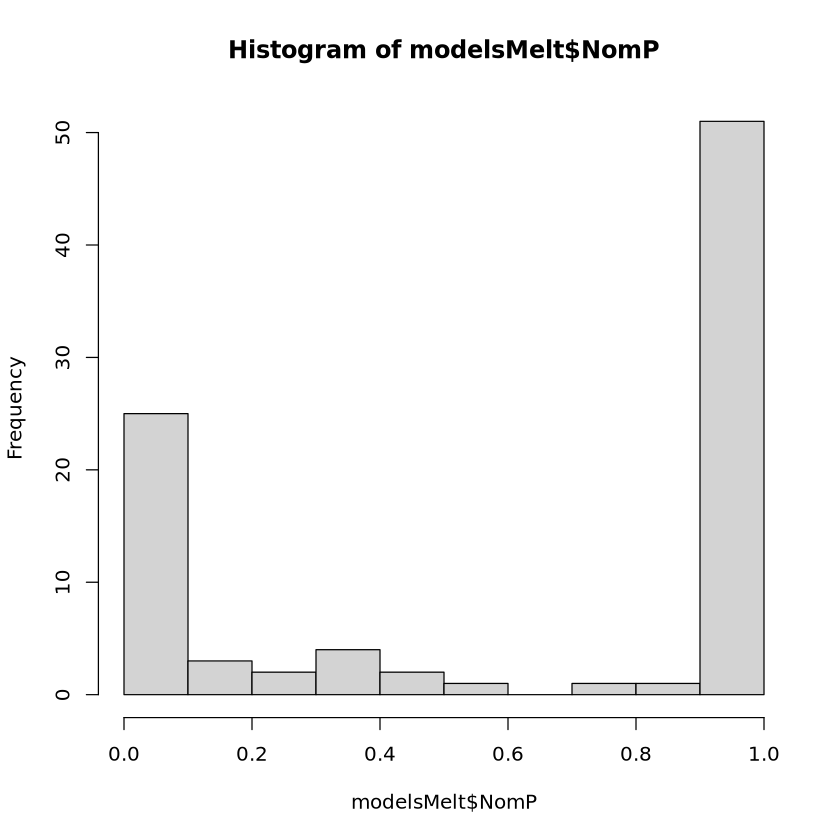

In [18]:
#MELT models for reading
    modelsCoef <- modelsDF %>% dplyr::select(contains("Coef"))
    modelsNom <- modelsDF %>% dplyr::select(contains("PNom"))
    modelsStdE <- modelsDF %>% dplyr::select(contains("StdE"))
    modelsMelt <- data.frame(chromState = -1, peakSet = -1, Coef = -1, StdE = -1, NomP = -1)

    for(mDex in 1:ncol(modelsCoef)) {
      
      metaFrame <- data.frame(chromState = rep(gsub(".Coef", "", colnames(modelsCoef)[mDex]), nrow(modelsDF)), peakSet = rownames(modelsCoef))
      metaFrame$Coef <- modelsCoef[,mDex]
      metaFrame$StdE <- modelsStdE[,mDex]
      metaFrame$NomP <- modelsNom[,mDex]
      modelsMelt <- rbind(modelsMelt, metaFrame)
      
    }
    
    modelsMelt <- modelsMelt[-1,]
    hist(modelsMelt$NomP)
    modelsMelt$Type <- glue("{cDex}")
    head(modelsMelt, n = 10)
    write.csv(modelsMelt, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/enrich/
                                        {cDex}_chromatinStateEnrichmentModels_AdultFemale_All_IndivMod_RoadMap_BGxGLM05_GLM005.csv"), row.names = FALSE, quote = FALSE)

In [19]:
Type1 <- read.csv(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/enrich/
                                        Type_1_chromatinStateEnrichmentModels_AdultFemale_All_IndivMod_RoadMap_BGxGLM05_GLM005.csv"))
Type2a <- read.csv(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/enrich/
                                        Type_2a_chromatinStateEnrichmentModels_AdultFemale_All_IndivMod_RoadMap_BGxGLM05_GLM005.csv"))
Type2x <- read.csv(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/enrich/
                                        Type_2x_chromatinStateEnrichmentModels_AdultFemale_All_IndivMod_RoadMap_BGxGLM05_GLM005.csv"))

Inter <- rbind(Type1, Type2a)
Final <- rbind(Inter, Type2x)
write.csv(Final, file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/enrich/
                                Fiber_chromatinStateEnrichmentModels_AdultFemale_All_IndivMod_RoadMap_BGxGLM05_GLM005.csv"), row.names = FALSE, quote = FALSE)

In [15]:
finalMelt <- read.table(file = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/enrich/
                                Fiber_chromatinStateEnrichmentModels_AdultFemale_All_IndivMod_RoadMap_BGxGLM05_GLM005.csv"), sep = ",", header = TRUE)
head(finalMelt, n = 10)
#finalMelt <- finalMelt[!(finalMelt$chromState %in% c("ZNF_gene_repeats", "Heterochromatin","Flanking_TSS","Flanking_transcription","Flanking_bivalent","Genic_enhancer")),]
finalMelt <- finalMelt[(finalMelt$peakSet %in% c("F GLM UP", "F GLM DOWN", "M GLM UP", "M GLM DOWN")),]#[(finalMelt$peakSet %in% c("F GLM", "M GLM")),]#

finalMelt$peakSet <- paste(finalMelt$Type, finalMelt$peakSet)
finalMelt$Type <- NULL
finalMelt$chromAge <- NULL
finalMelt$BonP <- p.adjust(finalMelt$NomP, method = "bonferroni", n=nrow(finalMelt))
stateList <- sort(unique(finalMelt$chromState))
head(finalMelt, n = 10)

,chromState,peakSet,Coef,StdE,NomP,Type
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>
1,Active_TSS,F GLM,-0.7300064,0.2533774,3.962866e-03,Type_1
2,Active_TSS,M GLM,-3.0253409,0.7684725,8.256717e-05,Type_1
3,Active_TSS,F GLM UP,0.9408972,0.3762187,1.238670e-02,Type_1
4,Active_TSS,M GLM UP,-2.7085950,1.3996585,5.296787e-02,Type_1
5,Active_TSS,F GLM DOWN,-1.8711480,0.3365901,2.711240e-08,Type_1
6,Active_TSS,M GLM DOWN,-3.1017328,0.9119898,6.712483e-04,Type_1
7,Strong_transcription,F GLM,-1.4697944,0.5060962,3.682168e-03,Type_1
8,Strong_transcription,M GLM,-14.1658608,444.3376738,9.745671e-01,Type_1
9,Strong_transcription,F GLM UP,-14.7270132,440.1442297,9.733081e-01,Type_1


,chromState,peakSet,Coef,StdE,NomP,BonP
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
3,Active_TSS,Type_1 F GLM UP,0.9408972,0.3762187,1.238670e-02,1.000000e+00
4,Active_TSS,Type_1 M GLM UP,-2.7085950,1.3996585,5.296787e-02,1.000000e+00
5,Active_TSS,Type_1 F GLM DOWN,-1.8711480,0.3365901,2.711240e-08,4.880232e-06
6,Active_TSS,Type_1 M GLM DOWN,-3.1017328,0.9119898,6.712483e-04,1.208247e-01
9,Strong_transcription,Type_1 F GLM UP,-14.7270132,440.1442297,9.733081e-01,1.000000e+00
10,Strong_transcription,Type_1 M GLM UP,-14.8476748,1209.3253589,9.902041e-01,1.000000e+00
11,Strong_transcription,Type_1 F GLM DOWN,-1.1420646,0.5081051,2.459574e-02,1.000000e+00
12,Strong_transcription,Type_1 M GLM DOWN,-14.8511621,729.7152797,9.837626e-01,1.000000e+00
15,Weak_transcription,Type_1 F GLM UP,-0.9256842,0.5241784,7.740057e-02,1.000000e+00


In [21]:
ColorCode_GLMUP <- "#882255"
ColorCode_GLMDOWN <- "#117733"

In [16]:
setOrder <- c("Type_1 F GLM UP", "Type_1 F GLM DOWN", "Type_2a F GLM UP", "Type_2a F GLM DOWN", "Type_2x F GLM UP", "Type_2x F GLM DOWN",
             "Type_1 M GLM UP", "Type_1 M GLM DOWN", "Type_2a M GLM UP", "Type_2a M GLM DOWN", "Type_2x M GLM UP", "Type_2x M GLM DOWN")

Thing <- finalMelt[finalMelt$chromState == stateList[1],] %>% arrange(match(peakSet, setOrder))
stateHeatCo <- data.frame(Active_enhancer = Thing$Coef) 
stateHeatBo <- data.frame(Active_enhancer = Thing$BonP)

for (state in stateList) {

  tempThing <- finalMelt[finalMelt$chromState == state,] %>% arrange(match(peakSet, setOrder))
  tempCo <- tempThing$Coef
  tempBo <- tempThing$BonP
  stateHeatCo <- cbind(stateHeatCo, tempCo)
  stateHeatBo <- cbind(stateHeatBo, tempBo)

}

stateHeatCo <- stateHeatCo[,-1]
stateHeatBo <- stateHeatBo[,-1]

colnames(stateHeatBo) <- stateList
colnames(stateHeatCo) <- stateList
rownames(stateHeatBo) <- setOrder
rownames(stateHeatCo) <- setOrder

#stateHeatCo$stretchEnhancer <- NULL
#stateHeatBo$stretchEnhancer <- NULL
  
stateHeatCo <- t(stateHeatCo)
 
#stateHeatCo <- stateHeatCo %>% data.frame() %>% arrange(match(colnames(stateHeatCo), setOrder))
#stateHeatBo <- stateHeatBo %>% data.frame() %>% arrange(match(colnames(stateHeatBo), setOrder))

metaGlob <- colnames(stateHeatCo)
Translator <- hash()
Translator[["F"]] <- "#FF0000"
Translator[["M"]] <- "#0000FF"
Translator[["Closing"]] <- "#CC6677"
Translator[["Opening"]] <- "#4AE4CB"
metaList <- c()
for (metaBit in metaGlob) {
  metaRow <- strsplit(metaBit, " ")
  if (length(metaRow[[1]]) == 3){metaRow[[1]]<- c(metaRow[[1]], "Tot")}
  for (dDex in 1:length(metaRow[[1]])) {
    
    if (metaRow[[1]][dDex] %in% hash::keys(Translator)){
      
      trans <- metaRow[[1]][dDex]#Translator[[metaRow[[1]][dDex]]]
      metaRow[[1]][dDex] <- trans
        
    }
      
  }
  metaList <- c(metaList, metaRow)
    
}
metaFrame <- as.data.frame(t(as.data.frame(metaList)))
colnames(metaFrame) <- c("Cell_Type","Sex","Model_Type","Cluster_Type")
rownames(metaFrame) <- metaGlob
metaFrame[metaFrame$Cluster_Type == "UP",]$Cluster_Type <- "Opening"
metaFrame[metaFrame$Cluster_Type == "DOWN",]$Cluster_Type <- "Closing"

  
stateHeatUnt <- as.matrix(stateHeatCo)

In [17]:
  col_palH <- c("#fee100","#ffe43d","#ffe75c","#ffea75","#ffee8e","#fff1a5","#fff4bb","#fff8d2","#fffbe8","#ffffff","#e2e3ea","#c6c7d5","#abadc0","#8f93ac","#757a98","#5b6185","#414a72","#25345f","#777369")#"#00204d")
  boundCol <- round(max(c(abs(max(stateHeatUnt))-9, abs(min(stateHeatUnt))))-9, digits = 1)
  brakers <- seq(-boundCol, boundCol, by = ((2*boundCol)/(length(col_palH))))
  
  annoCol <- data.frame(PATTERN = metaFrame$Cluster_Type, SEX = metaFrame$Sex, CELL_TYPE = metaFrame$Cell_Type)
  rownames(annoCol) <- rownames(metaFrame)
  annoColor <- list(PATTERN = c(Closing = "#CC6677", Opening = "#4AE4CB"), 
                    SEX = c(M = "#0000FF", F = "#FF0000"), 
                    CELL_TYPE = c(Type_1 = "#EEEEEE", Type_2a = "#888888", Type_2x = "#444444"))

In [68]:
stateHeatLab <- as.matrix(t(stateHeatBo))
stateHeatLab[stateHeatLab < 0.05] <- "*"
stateHeatLab[stateHeatLab >= 0.05] <- ""

pheatmap(stateHeatUnt, 
                    col = rev(col_palH),
                    cluster_rows = FALSE,
                    cluster_cols = FALSE,
                    breaks = brakers,
                    cexCol = 1, 
                    annotation_col = annoCol,
                    annotation_colors = annoColor,
                    #cutree_rows = 2,
                    #treeheight_row = 0,
                    #cutree_cols = 2,
                    treeheight_col = 16,
                    display_numbers = stateHeatLab,
                    filename = "/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/Fibers_ChromStateAll_AdultMale_GLMMNBFDR005TRUE_GLM05_Heatmap_RoadMap_ColFid.pdf",
                    #border_color=NA,
                    show_colnames = F,
                    main="Peak Set by Chromatin State Model Coefficient",
                    width = 10, height = 5, fontsize = 14,
                    )

In [17]:
finalMelt[finalMelt$chromState %in% c("Active_enhancer"),]

,chromState,peakSet,Coef,NomP,PBonferroni,chromSet
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>
39,Active_enhancer,Type_1 F GLM UP,0.31440490,6.440743e-02,3.864446e-01,Active_enhancer_
40,Active_enhancer,Type_1 M GLM UP,0.52873359,1.409927e-01,8.459559e-01,Active_enhancer_
41,Active_enhancer,Type_1 F GLM DOWN,1.36062239,1.808403e-42,1.085042e-41,Active_enhancer_
42,Active_enhancer,Type_1 M GLM DOWN,1.34722037,5.853436e-07,3.512062e-06,Active_enhancer_
129,Active_enhancer,Type_2a F GLM UP,0.36490318,4.269779e-03,2.561868e-02,Active_enhancer_
130,Active_enhancer,Type_2a M GLM UP,0.54195704,3.476572e-08,2.085943e-07,Active_enhancer_
131,Active_enhancer,Type_2a F GLM DOWN,1.23591595,1.021338e-58,6.128028e-58,Active_enhancer_
132,Active_enhancer,Type_2a M GLM DOWN,1.24283259,1.006291e-97,6.037745e-97,Active_enhancer_
219,Active_enhancer,Type_2x F GLM UP,0.08158207,7.871134e-01,1.000000e+00,Active_enhancer_


In [32]:
selectConcept <- c("Active_enhancer")
                                                     
selectFrame <- finalMelt[finalMelt$chromState %in% selectConcept,]
splitFrame <- data.frame(t(data.frame(strsplit(selectFrame$peakSet, split = " "))))
rownames(splitFrame) <- NULL
colnames(splitFrame) <- c("Type", "Sex", "Model", "Pattern")

selectFrame$Type <- splitFrame$Type
selectFrame$Sex <- splitFrame$Sex
selectFrame$Pattern <- splitFrame$Pattern
selectFrame[selectFrame$Pattern == "UP",]$Pattern <- "Opening"
selectFrame[selectFrame$Pattern == "DOWN",]$Pattern <- "Closing"

selectFrame$Pattern <- factor(selectFrame$Pattern, 
                              levels = c("Opening", "Closing"))
selectFrame$peakSet <- factor(selectFrame$peakSet, 
                              levels = c("Type_1 F GLM UP", "Type_1 F GLM DOWN", "Type_1 M GLM UP", "Type_1 M GLM DOWN",
                                        "Type_2a F GLM UP", "Type_2a F GLM DOWN", "Type_2a M GLM UP", "Type_2a M GLM DOWN",
                                        "Type_2x F GLM UP", "Type_2x F GLM DOWN", "Type_2x M GLM UP", "Type_2x M GLM DOWN"))


(selectFrame)
labelFrame <- selectFrame[selectFrame$BonP < 0.05, ] %>% dplyr::select(peakSet, Coef, Sex, Pattern, Type)
labelFrame[labelFrame$Coef < 0,]$Coef <- labelFrame[labelFrame$Coef < 0,]$Coef - 0.2
labelFrame[labelFrame$Coef > 0,]$Coef <- labelFrame[labelFrame$Coef > 0,]$Coef + 0.2

ColorCode_Female <- "#FF2222"
ColorCode_Male <- "#2222FF"

#selectFrame <- selectFrame %>% dplyr::filter(Type == "Type_1")

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/ATACEnrich_{selectConcept}_Bar.pdf"), width=10, height=10)
mygg <- ggplot(selectFrame, aes(x = peakSet, y = Coef, fill = Sex, pattern = Pattern)) +
  geom_bar_pattern(position = 'dodge', stat = "identity", pattern_fill = "black", pattern_color = "black", color = "black") +
  xlab("") + ylab("") + ggtitle(glue("")) + 
  geom_vline(xintercept = 0) +
  scale_fill_manual(values = c(ColorCode_Female,ColorCode_Male)) +
  scale_pattern_manual(values = c(Opening = "none", Closing = "stripe")) +
  scale_y_continuous(breaks=seq(-4,4,1), limits = c(-4,4)) + theme_bw() +
  theme(text=element_text(size=22), axis.title.y=element_blank(),
        axis.text.y=element_blank(),
        axis.ticks.y=element_blank()) +
  guides(pattern = guide_legend(override.aes = list(fill = "white")),
         fill = guide_legend(override.aes = list(pattern = "none")))+ 
  geom_text(data = labelFrame, label = "*", size=10) 
mygg
dev.off()

,chromState,peakSet,Coef,StdE,NomP,BonP,Type,Sex,Pattern
,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<fct>
27,Active_enhancer,Type_1 F GLM UP,0.01910265,0.31479691,9.516121e-01,1.000000e+00,Type_1,F,Opening
28,Active_enhancer,Type_1 M GLM UP,1.25286594,0.72280553,8.303570e-02,1.000000e+00,Type_1,M,Opening
29,Active_enhancer,Type_1 F GLM DOWN,1.55260644,0.16290968,1.565669e-21,2.818204e-19,Type_1,F,Closing
30,Active_enhancer,Type_1 M GLM DOWN,0.92961902,0.38574811,1.595637e-02,1.000000e+00,Type_1,M,Closing
117,Active_enhancer,Type_2a F GLM UP,0.43665886,0.19913596,2.832413e-02,1.000000e+00,Type_2a,F,Opening
118,Active_enhancer,Type_2a M GLM UP,0.49967711,0.13714641,2.690763e-04,4.843373e-02,Type_2a,M,Opening
119,Active_enhancer,Type_2a F GLM DOWN,1.39188878,0.10576995,1.499038e-39,2.698268e-37,Type_2a,F,Closing
120,Active_enhancer,Type_2a M GLM DOWN,1.26856788,0.07723754,1.282815e-60,2.309067e-58,Type_2a,M,Closing
207,Active_enhancer,Type_2x F GLM UP,0.00000000,-1.00000000,1.000000e+00,1.000000e+00,Type_2x,F,Opening


pdf 
  2

In [33]:
selectFrame$Coef_CU <- selectFrame$Coef + selectFrame$StdE*1.959964#1.64485#
selectFrame$Coef_CL <- selectFrame$Coef - selectFrame$StdE*1.959964#1.64485#
selectFrame$Confidence <- (selectFrame$BonP < 0.05)
selectFrame <- selectFrame[selectFrame$Pattern == "Closing",]
selectFrame$peakSet <- c("Type 1 Female Closing Chromatin", "Type 1 Male Closing Chromatin", 
                         "Type 2a Female Closing Chromatin", "Type 2a Male Closing Chromatin",
                         "Type 2x Female Closing Chromatin", "Type 2x Male Closing Chromatin")
setOrder <- c("Type 1 Female Closing Chromatin", "Type 1 Male Closing Chromatin",
                                        "Type 2a Female Closing Chromatin", "Type 2a Male Closing Chromatin",
                                        "Type 2x Female Closing Chromatin", "Type 2x Male Closing Chromatin")
selectFrame$peakSet <- factor(selectFrame$peakSet, 
                              levels = setOrder)
selectFrame

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/enrich/ATACEnrich_{selectConcept}_Line.pdf"), width=5, height=4)
myplot <- ggplot(selectFrame, aes(factor(peakSet, levels = (setOrder)), Coef)) + 
  geom_point(size = 3) + 
  geom_errorbar(aes(ymin = Coef_CL, ymax = Coef_CU)) + geom_hline(yintercept = 0, linetype = "dashed") +
  theme_bw() + theme(text=element_text(size=24), axis.text.x=element_blank(), legend.position="none") + #scale_color_manual(values = c("#000000", "#FF0000")) +
    scale_y_continuous(breaks=seq(-5,5,1), limits = c(-5,5)) +
  ylab("") + xlab("") + ggtitle(glue("")) 
print(myplot)
dev.off()

,chromState,peakSet,Coef,StdE,NomP,BonP,Type,Sex,Pattern,Coef_CU,Coef_CL,Confidence
,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<fct>,<dbl>,<dbl>,<lgl>
29,Active_enhancer,Type 1 Female Closing Chromatin,1.552606,0.16290968,1.565669e-21,2.818204e-19,Type_1,F,Closing,1.871904,1.2333093,TRUE
30,Active_enhancer,Type 1 Male Closing Chromatin,0.929619,0.38574811,1.595637e-02,1.000000e+00,Type_1,M,Closing,1.685671,0.1735666,FALSE
119,Active_enhancer,Type 2a Female Closing Chromatin,1.391889,0.10576995,1.499038e-39,2.698268e-37,Type_2a,F,Closing,1.599194,1.1845835,TRUE
120,Active_enhancer,Type 2a Male Closing Chromatin,1.268568,0.07723754,1.282815e-60,2.309067e-58,Type_2a,M,Closing,1.419951,1.1171851,TRUE
209,Active_enhancer,Type 2x Female Closing Chromatin,2.503691,0.70688962,3.973437e-04,7.152187e-02,Type_2x,F,Closing,3.889169,1.1182130,FALSE
210,Active_enhancer,Type 2x Male Closing Chromatin,1.349674,0.15381730,1.716216e-18,3.089189e-16,Type_2x,M,Closing,1.651151,1.0481979,TRUE


pdf 
  2